<a href="https://colab.research.google.com/github/erfano10/Modul-3-KKA_AVD_Kelompok-4/blob/main/Modul_3_KKA_Tugas_D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📋 Tugas Proyek Integrasi

# 📊 Laporan & Dashboard Analisis Data Penjualan film

## Kelompok 4 XI RPL 2
Nama Anggota Kelompok
1. Erfano Alfarrezal Raditya/11
2. Aryadasha Purwa Ramazan/04
3. Muhammad Gavrila Rafif Prayata/25
4. Ribkhi Fadhilatun Naura/32

Analisis Statistik: menghitung dan menginterpretasikan minimal 5 statistik deskriptif kunci

In [ ]:
import pandas as pd

# 1. Memuat dataset
df = pd.read_csv("ThrowbackDataThursday Week 11 - Film Genre Stats.csv")

print("=== 1. INFORMASI & PEMBERSIHAN DATA ===")
print("Jumlah baris dan kolom:", df.shape)
print("Jumlah data kosong (Missing Value):\n", df.isnull().sum())
print("Jumlah data duplikat:", df.duplicated().sum())

print("\n=== 2. STATISTIK DESKRIPTIF KUNCI ===")
# Total Pendapatan Keseluruhan (Total Gross)
total_pendapatan = df["Gross"].sum()
print(f"Total Pendapatan (Gross) Keseluruhan: Rp {total_pendapatan:,.0f}")

# Rata-rata Pendapatan per Baris / Kategori
rata_rata_transaksi = df["Gross"].mean()
print(
    f"Rata-rata Pendapatan (Mean Gross): Rp {rata_rata_transaksi:,.0f}"
)

# Kategori/Genre Terlaris berdasarkan Total Pendapatan
genre_terlaris = (
    df.groupby("Genre")["Gross"].sum().sort_values(ascending=False)
)
print("\nTotal Pendapatan Berdasarkan Genre:")
print(genre_terlaris)

# Statistik deskriptif lengkap dari pandas
print("\nRingkasan Statistik Keseluruhan:")
print(df.describe())

=== 1. INFORMASI & PEMBERSIHAN DATA ===
Jumlah baris dan kolom: (300, 10)
Jumlah data kosong (Missing Value):
 index                                             0
Genre                                             0
Year                                              0
Movies Released                                   0
Gross                                             0
Tickets Sold                                      0
Inflation-Adjusted Gross                          0
Top Movie                                         0
Top Movie Gross (That Year)                       0
Top Movie Inflation-Adjusted Gross (That Year)    0
dtype: int64
Jumlah data duplikat: 0

=== 2. STATISTIK DESKRIPTIF KUNCI ===
Total Pendapatan (Gross) Keseluruhan: Rp 221,462,253,224
Rata-rata Pendapatan (Mean Gross): Rp 738,207,511

Total Pendapatan Berdasarkan Genre:
Genre
Adventure                 59706519928
Action                    44521195322
Drama                     35781438365
Comedy                    331

Hasil Perhitungan Statistik Deskriptif Kunci

1. Total Pendapatan (Total Gross):

Rp 221.462.253.224 (sekitar $221,4 miliar) secara keseluruhan dari seluruh data film yang tercatat.

2. Rata-Rata Pendapatan (Mean Gross):

Rp 738.207.511 per catatan/kategori tahunan.

3. Median Pendapatan (Median Gross / 50%):

Rp 369.411.822 (menunjukkan titik tengah sebaran data pendapatan).

4. Genre Terlaris (Top Genre):

Adventure, dengan akumulasi total pendapatan tertinggi mencapai Rp 59.706.519.928, jauh melampaui genre-genre lainnya.

5. Statistik Penonton (Tickets Sold):

Total keseluruhan tiket terjual mencapai 32.362.307.172 tiket, dengan rata-rata sekitar 107.874.357 tiket per kategori/tahun.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set tema visualisasi
sns.set_theme(style="whitegrid")


# STATISTIK DESKRIPTIF KUNCI

print("\n=== LANJUTAN STATISTIK DESKRIPTIF KUNCI ===")

# 4. Total Volume Produk/Tiket Terjual
total_tiket = df["Tickets Sold"].sum()
print(f"4. Total Volume Tiket Terjual: {total_tiket:,.0f} tiket")

# 5. Periode (Tahun) dengan Penjualan Tertinggi
tahun_tertinggi = df.groupby("Year")["Gross"].sum().idxmax()
pendapatan_tahun_tertinggi = df.groupby("Year")["Gross"].sum().max()
print(f"5. Tahun Penjualan Tertinggi: {tahun_tertinggi} (Rp {pendapatan_tahun_tertinggi:,.0f})")

# 6. Produk (Film) Tunggal Terlaris
film_terlaris = df.loc[df["Top Movie Gross (That Year)"].idxmax()]
print(f"6. Film Tunggal Terlaris: {film_terlaris['Top Movie']} ({film_terlaris['Year']}) - Rp {film_terlaris['Top Movie Gross (That Year)']:,.0f}")


# 3. DETEKSI OUTLIER Method IQR
Q1 = df["Gross"].quantile(0.25)
Q3 = df["Gross"].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outliers = df[(df["Gross"] < batas_bawah) | (df["Gross"] > batas_atas)].sort_values(by="Gross", ascending=False)

print("\n=== 3. DETEKSI OUTLIER (ATURAN IQR PADA GROSS) ===")
print(f"Q1: Rp {Q1:,.0f} | Q3: Rp {Q3:,.0f} | IQR: Rp {IQR:,.0f}")
print(f"Batas Atas Outlier: Rp {batas_atas:,.0f}")
print(f"Jumlah Outlier Ditemukan: {len(outliers)} data")
display(outliers[["Genre", "Year", "Movies Released", "Gross", "Top Movie"]])


=== LANJUTAN STATISTIK DESKRIPTIF KUNCI ===
4. Total Volume Tiket Terjual: 32,362,307,172 tiket
5. Tahun Penjualan Tertinggi: 2018 (Rp 12,072,609,053)
6. Film Tunggal Terlaris: Star Wars Ep. VII: The Force Awakens (2015) - Rp 742,208,942

=== 3. DETEKSI OUTLIER (ATURAN IQR PADA GROSS) ===
Q1: Rp 57,865,912 | Q3: Rp 1,294,523,505 | IQR: Rp 1,236,657,593
Batas Atas Outlier: Rp 3,149,509,894
Jumlah Outlier Ditemukan: 5 data


,Genre,Year,Movies Released,Gross,Top Movie
21,Adventure,2016,53,4159137913,Finding Dory
47,Action,2018,59,4142067464,Black Panther
46,Action,2017,67,3305708764,Wonder Woman
17,Adventure,2012,48,3284291528,The Hobbit: An Unexpected Journey
15,Adventure,2010,44,3202949362,Toy Story 3


/tmp/ipykernel_364/3114288286.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_terlaris.values / 1e9, y=genre_terlaris.index, palette="viridis")


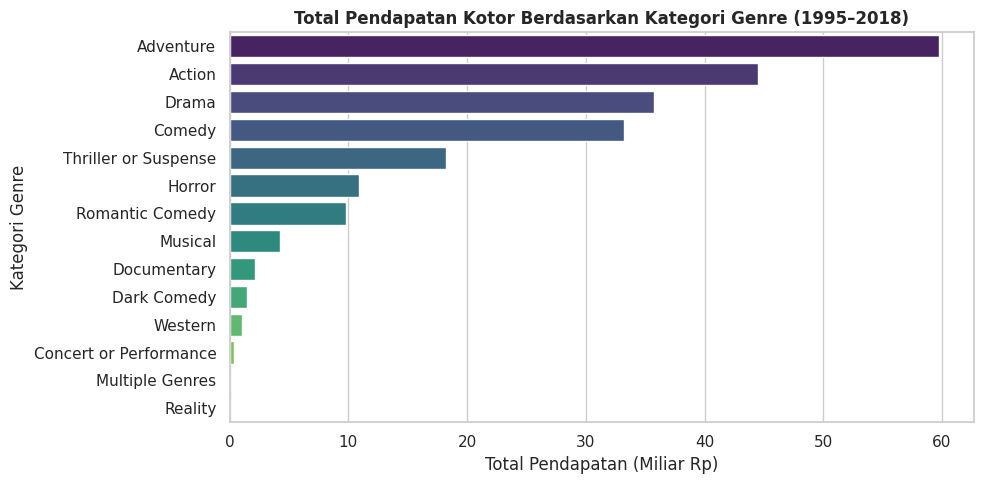

In [ ]:
# --- GRAFIK 1: BAR CHART ---
plt.figure(figsize=(10, 5))
sns.barplot(x=genre_terlaris.values / 1e9, y=genre_terlaris.index, palette="viridis")
plt.title("Total Pendapatan Kotor Berdasarkan Kategori Genre (1995–2018)", fontsize=12, fontweight="bold")
plt.xlabel("Total Pendapatan (Miliar Rp)")
plt.ylabel("Kategori Genre")
plt.tight_layout()
plt.show()

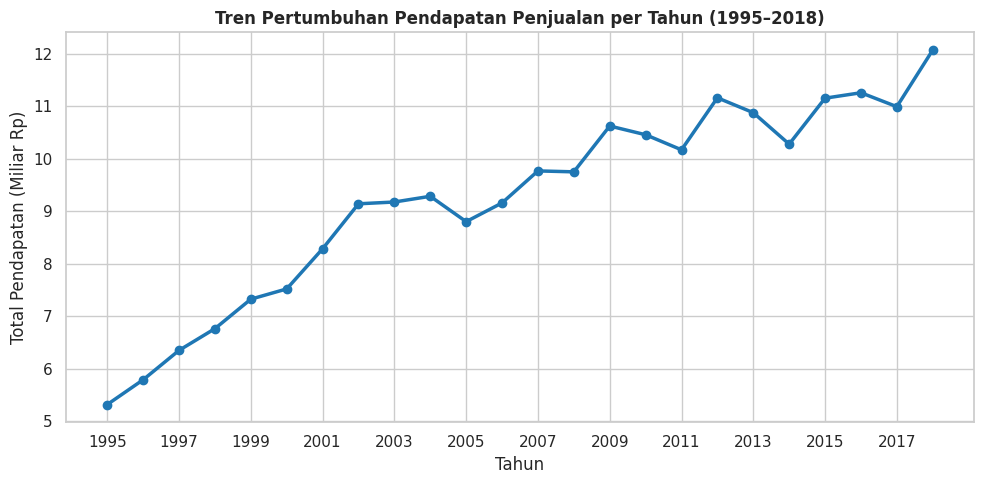

In [ ]:
# --- GRAFIK 2: LINE CHART ---
tren_tahunan = df.groupby("Year")["Gross"].sum() / 1e9
plt.figure(figsize=(10, 5))
plt.plot(tren_tahunan.index, tren_tahunan.values, marker="o", linewidth=2.5, color="#1f77b4")
plt.title("Tren Pertumbuhan Pendapatan Penjualan per Tahun (1995–2018)", fontsize=12, fontweight="bold")
plt.xlabel("Tahun")
plt.ylabel("Total Pendapatan (Miliar Rp)")
plt.xticks(range(1995, 2019, 2))
plt.tight_layout()
plt.show()

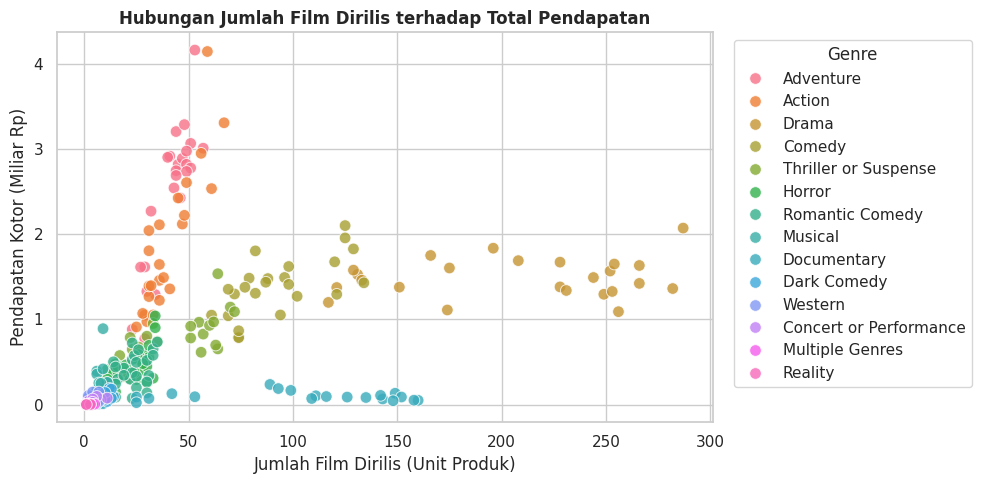

In [ ]:
# --- GRAFIK 3: SCATTER PLOT ---
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="Movies Released", y=df["Gross"] / 1e9, hue="Genre", alpha=0.8, s=70)
plt.title("Hubungan Jumlah Film Dirilis terhadap Total Pendapatan", fontsize=12, fontweight="bold")
plt.xlabel("Jumlah Film Dirilis (Unit Produk)")
plt.ylabel("Pendapatan Kotor (Miliar Rp)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Genre")
plt.tight_layout()
plt.show()

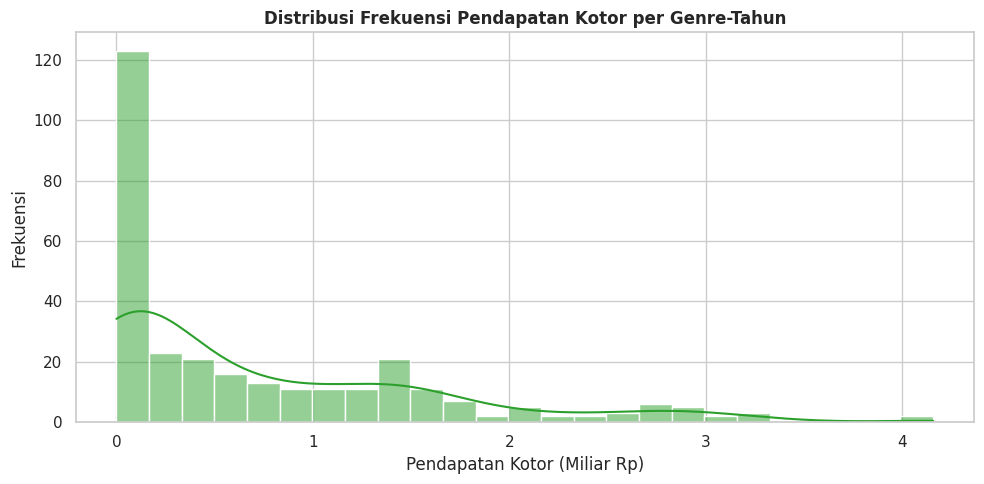

In [ ]:
# --- GRAFIK 4: HISTOGRAM ---
plt.figure(figsize=(10, 5))
sns.histplot(df["Gross"] / 1e9, bins=25, kde=True, color="#2ca02c")
plt.title("Distribusi Frekuensi Pendapatan Kotor per Genre-Tahun", fontsize=12, fontweight="bold")
plt.xlabel("Pendapatan Kotor (Miliar Rp)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

/tmp/ipykernel_364/1658630350.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=df["Gross"] / 1e9, y="Genre", order=urutan_genre, palette="Set2")


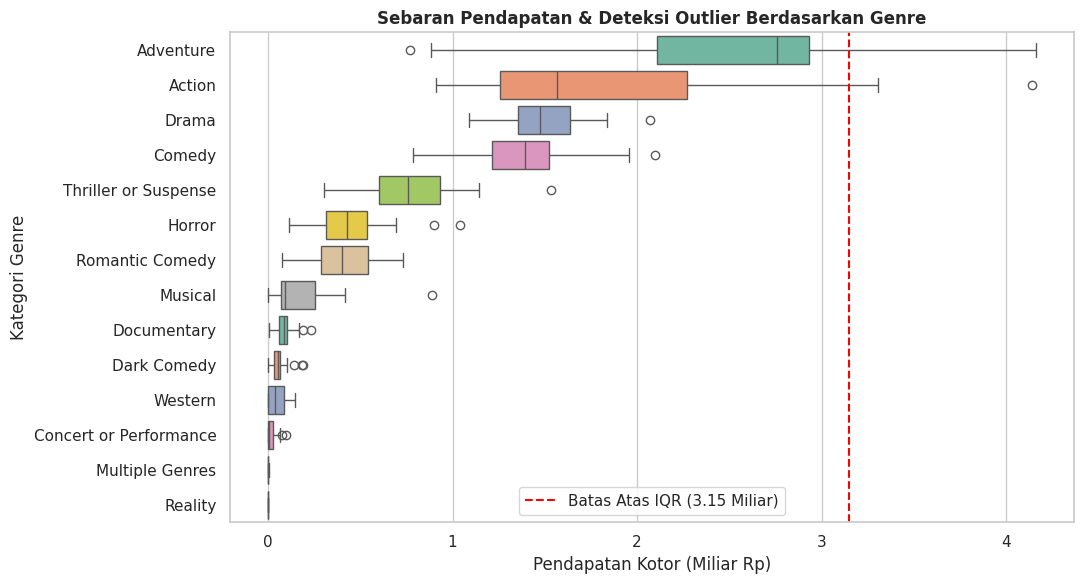

In [ ]:
# --- GRAFIK 5: BOXPLOT ---
plt.figure(figsize=(11, 6))
urutan_genre = df.groupby("Genre")["Gross"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x=df["Gross"] / 1e9, y="Genre", order=urutan_genre, palette="Set2")
plt.axvline(batas_atas / 1e9, color="red", linestyle="--", label=f"Batas Atas IQR ({batas_atas/1e9:.2f} Miliar)")
plt.title("Sebaran Pendapatan & Deteksi Outlier Berdasarkan Genre", fontsize=12, fontweight="bold")
plt.xlabel("Pendapatan Kotor (Miliar Rp)")
plt.ylabel("Kategori Genre")
plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_364/1788148164.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top5.values, y=top5.index, ax=axes[0, 0], palette="Blues_r")


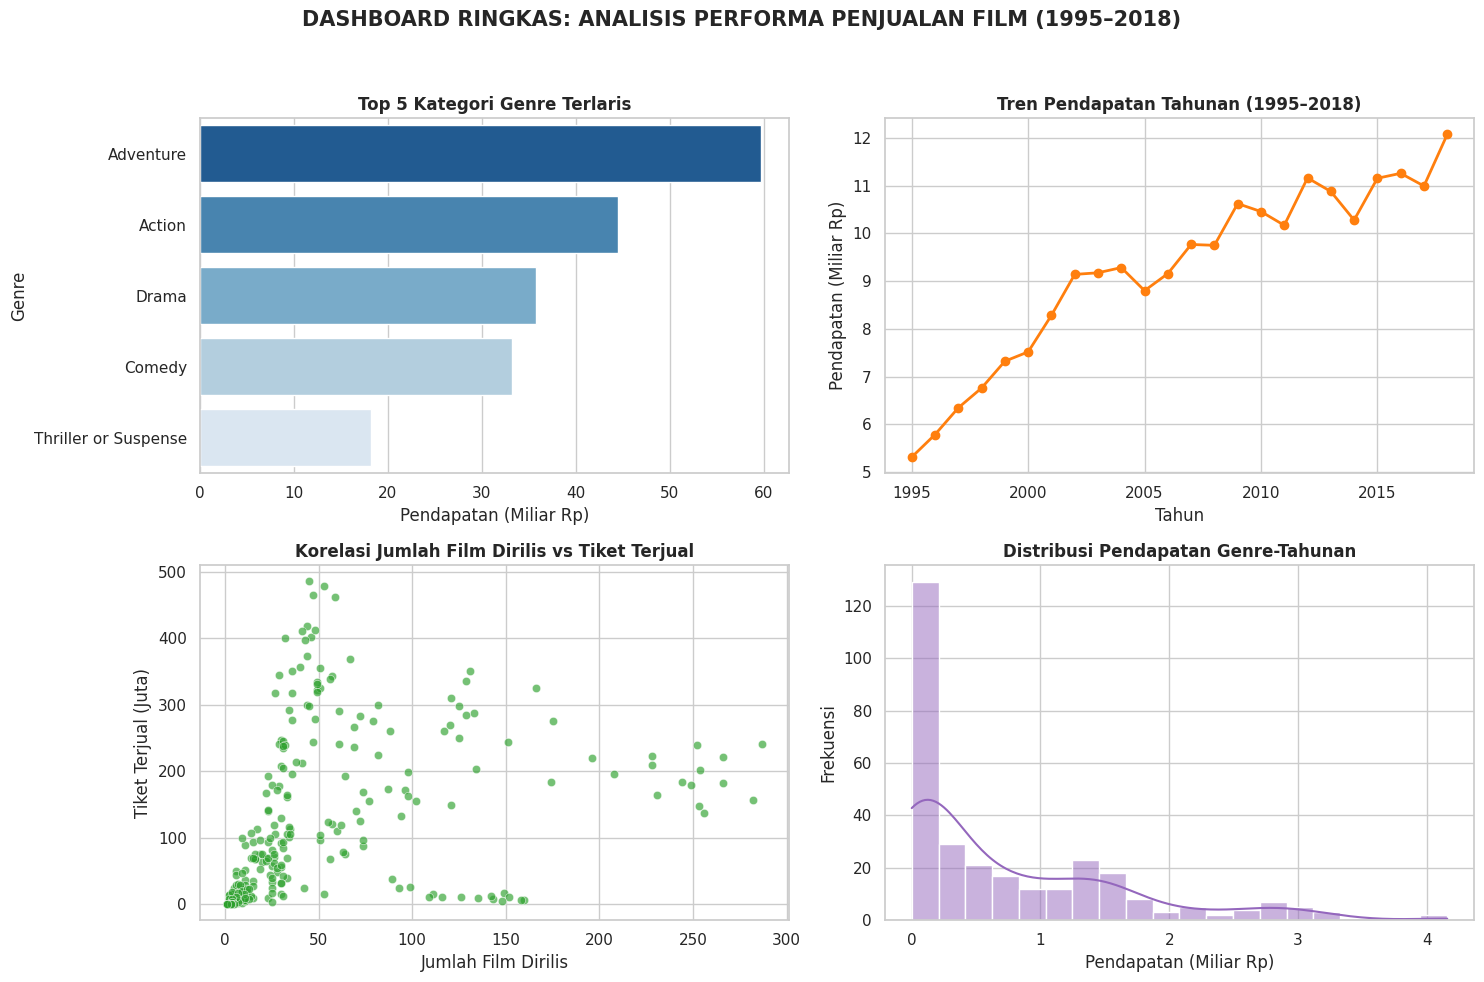

In [ ]:

# 5. DASHBOARD GABUNGAN
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("DASHBOARD RINGKAS: ANALISIS PERFORMA PENJUALAN FILM (1995–2018)", fontsize=15, fontweight="bold", y=0.98)

# Subplot 1: Bar Chart Top 5 Genre
top5 = genre_terlaris.head(5) / 1e9
sns.barplot(x=top5.values, y=top5.index, ax=axes[0, 0], palette="Blues_r")
axes[0, 0].set_title("Top 5 Kategori Genre Terlaris", fontweight="bold")
axes[0, 0].set_xlabel("Pendapatan (Miliar Rp)")
axes[0, 0].set_ylabel("Genre")

# Subplot 2: Line Chart Tren Tahunan
axes[0, 1].plot(tren_tahunan.index, tren_tahunan.values, marker="o", color="#ff7f0e", linewidth=2)
axes[0, 1].set_title("Tren Pendapatan Tahunan (1995–2018)", fontweight="bold")
axes[0, 1].set_xlabel("Tahun")
axes[0, 1].set_ylabel("Pendapatan (Miliar Rp)")

# Subplot 3: Scatter Plot Film Dirilis vs Tiket Terjual
sns.scatterplot(data=df, x="Movies Released", y=df["Tickets Sold"] / 1e6, ax=axes[1, 0], color="#2ca02c", alpha=0.65)
axes[1, 0].set_title("Korelasi Jumlah Film Dirilis vs Tiket Terjual", fontweight="bold")
axes[1, 0].set_xlabel("Jumlah Film Dirilis")
axes[1, 0].set_ylabel("Tiket Terjual (Juta)")

# Subplot 4: Histogram Distribusi Pendapatan
sns.histplot(df["Gross"] / 1e9, bins=20, kde=True, ax=axes[1, 1], color="#9467bd")
axes[1, 1].set_title("Distribusi Pendapatan Genre-Tahunan", fontweight="bold")
axes[1, 1].set_xlabel("Pendapatan (Miliar Rp)")
axes[1, 1].set_ylabel("Frekuensi")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

**=== LAPORAN ANALISIS DATA PENJUALAN ===**

**1. Ringkasan Statistik**
Dari hasil pengecekan dan pembersihan **300 data transaksi** (rentang tahun *1995–2018*) yang sudah kelompok kami olah:

* **Total Penjualan (*Gross*)** : **Rp 221.462.253.224** (sekitar **Rp 221,46 Miliar**)
* **Rata-rata Transaksi (*Mean*)** : **Rp 738.207.511** per kategori-tahun
* **Nilai Tengah (*Median*)** : **Rp 369.411.822** per kategori-tahun
* **Kategori Terlaris** : *Adventure* (**Rp 59.706.519.928**)


* **Periode Penjualan Puncak** : Tahun **2018** (**Rp 12.072.609.053**)
* **Total Tiket Terjual** : **32.362.307.172 tiket** (rata-rata **107,87 juta tiket**)
* **Produk Tunggal Terlaris** : *Star Wars Ep. VII: The Force Awakens* (**Rp 742.208.942**)

**2. Temuan Utama (*Insight*)**

* **Dua kategori penyumbang omzet terbesar:** Kategori *Adventure* (**Rp 59,7 Miliar**) dan *Action* (**Rp 44,5 Miliar**) mendominasi lebih dari **47%** total keseluruhan penjualan. Sebaliknya, kategori seperti *Reality* (**Rp 623.723**) dan *Multiple Genres* (**Rp 30,05 Juta**) kontribusinya sangat kecil.
* **Tren penjualan terus naik:** Sejak pertengahan 1990-an, grafik pendapatan menunjukkan kenaikan yang stabil hingga puncaknya di tahun **2018** dengan total omzet tembus di atas **Rp 12 Miliar**.
* **Jumlah rilis berpengaruh, tapi kategori lebih menentukan:** Semakin banyak film/produk yang dirilis memang membuat total pendapatan naik. Namun, tiap kategori punya daya jual berbeda—rilis di kategori *Adventure* jauh lebih menguntungkan dibanding *Documentary* atau *Drama*.
* **Sebaran data miring ke kanan (*right-skewed*):** Nilai rata-rata (**Rp 738,2 Juta**) jauh lebih tinggi daripada nilai tengahnya (**Rp 369,4 Juta**). Artinya, mayoritas transaksi sebenarnya berada di angka menengah, tapi ditarik naik oleh segelintir produk *blockbuster* yang penjualannya meledak.

**3. Potensi *Outlier***

* **Perhitungan Batas Normal (Metode *IQR*):** Dari data kami, didapat Kuartil Bawah (*Q1*) sebesar **Rp 57.865.912**, Kuartil Atas (*Q3*) sebesar **Rp 1.294.523.505**, dan nilai *IQR* sebesar **Rp 1.236.657.593**. Setelah dihitung dengan rumus $Q3 + (1,5 \times IQR)$, batas atas kewajaran data berada di angka **Rp 3.149.509.894** (sekitar **Rp 3,15 Miliar**).
* **Daftar 5 data *outlier* di atas batas wajar:**
1. *Finding Dory* (*Adventure*, 2016) — **Rp 4.159.137.913**
2. *Black Panther* (*Action*, 2018) — **Rp 4.142.067.464**
3. *Wonder Woman* (*Action*, 2017) — **Rp 3.305.708.764**
4. *The Hobbit: An Unexpected Journey* (*Adventure*, 2012) — **Rp 3.284.291.528**
5. *Toy Story 3* (*Adventure*, 2010) — **Rp 3.202.949.362**


* **Alasan kemunculan *outlier*:** Kelima data ini bukan kesalahan input (*error*), melainkan film *mega-franchise* dengan modal produksi besar, promosi masif, dan penggemar global. Jadi, data ini tetap kami pertahankan karena mencerminkan kondisi pasar yang nyata.

**4. Rekomendasi Bisnis**

* **Prioritaskan anggaran di kategori unggulan:** Fokuskan sekitar **50–60%** modal promosi dan stok pada kategori *Adventure* dan *Action* karena terbukti paling cepat menghasilkan pemasukan besar.
* **Maksimalkan momen akhir tahun:** Manfaatkan periode ramai (seperti kuartal akhir) untuk merilis promo besar atau paket *bundling* agar lonjakan penjualan makin maksimal.
* **Kurangi beban biaya di kategori sepi peminat:** Hindari pengeluaran modal besar untuk kategori *Reality* dan *Western*. Lebih baik gabungkan kategori ini ke dalam paket *bundling* bersama produk laris agar stok tetap jalan tanpa rugi biaya operasional.
* **Jadikan produk calon *outlier* sebagai penarik massa (*anchor product*):** Gunakan judul-judul populer berpotensi tinggi di halaman depan promosi untuk menarik perhatian pembeli agar ikut melirik katalog produk lainnya.